## 1) First mount Google Drive:

### Step 1: Mount Drive


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2) Check that the file exists

In [4]:
import os

os.path.exists('/content/drive/MyDrive/Ratings.csv')

True

In [ ]:
# /content/drive/MyDrive/Ratings.csv

###Step 3. Import libraries  

In [5]:
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity


### Step 4: Load dataset


In [6]:
df = pd.read_csv('/content/drive/MyDrive/Ratings.csv')

In [7]:
# Step 5: View first rows
df.head()

,Name,Rating
0,Nandan,5
1,Kapil,6
2,Girish,8
3,Sonali,7


### Step 6. Create user item matrix  

In [8]:
user_item_matrix = df.pivot_table(
    index='Name',
    values='Rating'
)

###Handle missing values  

In [9]:
user_item_matrix.fillna(0, inplace=True)


###Compute user similarity  

In [10]:
user_similarity = cosine_similarity(user_item_matrix)
user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_item_matrix.index,
    columns=user_item_matrix.index
)


###Find similar users  

In [11]:
user_id = 'Nandan'

similar_users = user_similarity_df[user_id].sort_values(ascending=False)
similar_users.head()

,Nandan
Name,
Girish,1.0
Kapil,1.0
Nandan,1.0
Sonali,1.0


### Recommend items  

In [12]:
similar_users = similar_users[similar_users.index != user_id]
weighted_ratings = user_item_matrix.loc[similar_users.index].T.dot(similar_users)
recommendations = weighted_ratings.sort_values(ascending=False)


In [13]:
#Remove already rated items.
already_rated = user_item_matrix.loc[user_id]
already_rated = already_rated[already_rated > 0].index
recommendations = recommendations.drop(already_rated)
recommendations.head(5)


,0


##Part 1: Statistical Techniques

### 1. Mean (Average Rating)
Purpose: Average rating given by users.

In [14]:
df['Rating'].mean()

np.float64(6.5)

###2. Median

Purpose: Middle rating.

In [15]:
df['Rating'].median()

6.5

###3. Mode

Purpose: Most frequent rating.

In [16]:
df['Rating'].mode()

,Rating
0,5
1,6
2,7
3,8


###4. Variance

Purpose: Measures spread of ratings.

In [17]:
df['Rating'].var()

1.6666666666666667

###5. Standard Deviation

Purpose: Average deviation from mean.

In [18]:
df['Rating'].std()

1.2909944487358056

###6. Minimum Rating

In [19]:
df['Rating'].min()

5

###7. Maximum Rating

In [20]:
df['Rating'].max()

8

### 8. Range

In [21]:
df['Rating'].max() - df['Rating'].min()

3

### 9. Quartiles

In [22]:
df['Rating'].quantile([0.25,0.5,0.75])

,Rating
0.25,5.75
0.50,6.50
0.75,7.25


### 10. IQR
Purpose

Outlier detection

In [23]:
Q1 = df['Rating'].quantile(0.25)
Q3 = df['Rating'].quantile(0.75)

IQR = Q3 - Q1
print(IQR)

1.5


### Distribution Analysis
11. Skewness

In [24]:
df['Rating'].skew()

np.float64(0.0)

###12. Kurtosis

In [25]:
df['Rating'].kurt()

np.float64(-1.1999999999999993)

In [26]:
print(df.columns)

Index(['Name', 'Rating'], dtype='object')


In [27]:
df_numerical = df.select_dtypes(include=np.number)
display(df_numerical.head())

,Rating
0,5
1,6
2,8
3,7


###Complete Statistical Summary

In [28]:
df.describe()

,Rating
count,4.000000
mean,6.500000
std,1.290994
min,5.000000
25%,5.750000
50%,6.500000
75%,7.250000
max,8.000000


##Part 2: Visualization


###1) Histogram

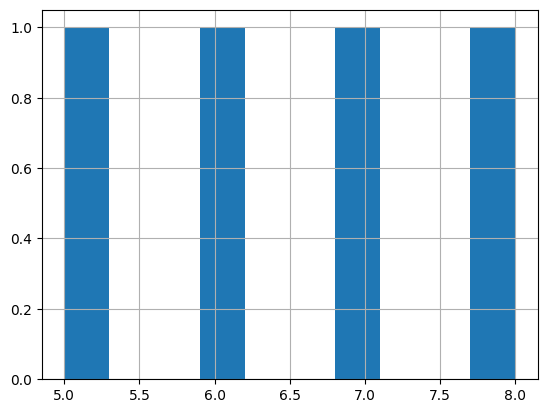

In [29]:
import matplotlib.pyplot as plt

df['Rating'].hist()
plt.show()

###2) Boxplot

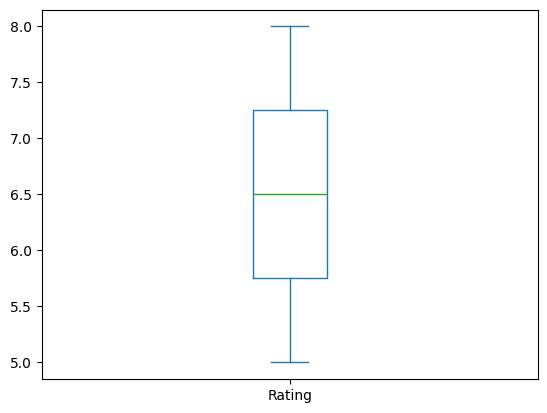

In [30]:
df['Rating'].plot.box()
plt.show()

###3) Density Plot

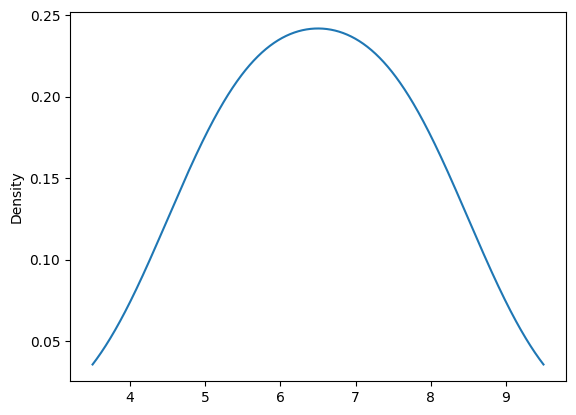

In [31]:
df['Rating'].plot(kind='density')
plt.show()

##Part 3: Machine Learning Algorithms

###1. Linear Regression
Purpose

Predict rating.

In [43]:
# Define features (X) and target (y)
X = df[['Rating']]  # Using 'Rating' as a feature for demonstration, though not meaningful for prediction
y = df['Rating']    # Target variable

In [44]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (3, 1)
y_train shape: (3,)
X_test shape: (1, 1)
y_test shape: (1,)


In [38]:
# from sklearn.linear_model import LinearRegression

# model = LinearRegression()
# model.fit(X_train,y_train)

# pred = model.predict(X_test)

###2. Decision Tree

In [45]:
from sklearn.tree import DecisionTreeRegressor

model = DecisionTreeRegressor()
model.fit(X_train,y_train)

DecisionTreeRegressor()

A). Make Predictions

In [46]:
model.fit(X_train,y_train)
pred = model.predict(X_test)

print(pred[:10])

[5.]


###B). Compare Actual vs Predicted

In [41]:
result = pd.DataFrame({
    'Actual': y_test,
    'Predicted': pred
})

result.head(10)

,Actual,Predicted
1,6,5.0


###C). Calculate MAE

In [42]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, pred)

print("MAE =", mae)

MAE = 1.0


###D). Calculate MSE

In [47]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, pred)

print("MSE =", mse)

MSE = 1.0


###E). Calculate RMSE

In [64]:
import numpy as np

rmse = np.sqrt(mse)

print("RMSE =", rmse)

RMSE = 0.9989466782182668


###F). Calculate R² Score

In [65]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, pred)

print("R2 Score =", r2)

R2 Score = nan


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


###G). Visualize Actual vs Predicted

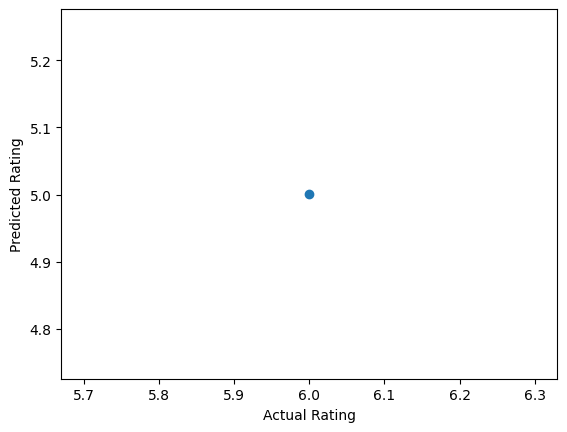

In [66]:
import matplotlib.pyplot as plt

plt.scatter(y_test, pred)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")

plt.show()

###H). Visualize the Decision Tree

For a small tree:

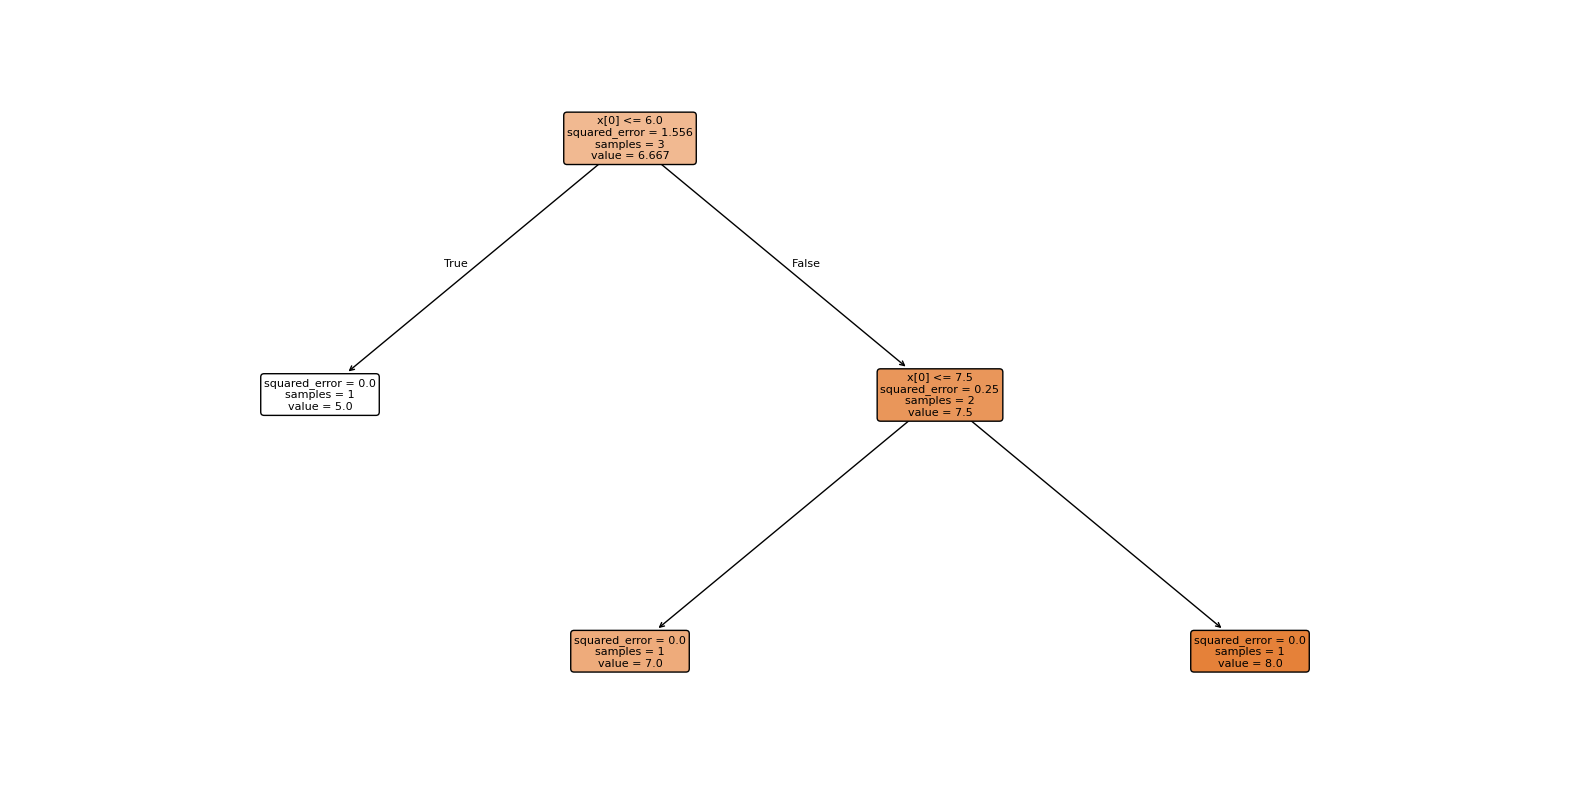

In [68]:
from sklearn.tree import plot_tree, DecisionTreeRegressor
import matplotlib.pyplot as plt

# Re-instantiate and fit the DecisionTreeRegressor to ensure 'model' is of the correct type
model = DecisionTreeRegressor()
model.fit(X_train, y_train)

plt.figure(figsize=(20,10))

plot_tree(
    model,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()

###I).Feature Importance

For your Ratings dataset (user_id, item_id):

In [69]:
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model.feature_importances_
})

print(importance)

  Feature  Importance
0  Rating         1.0


###J).

In [48]:
pred = model.predict(X_test)

from sklearn.metrics import mean_absolute_error, r2_score

print("MAE =", mean_absolute_error(y_test, pred))
print("R2 =", r2_score(y_test, pred))

pd.DataFrame({
    "Actual": y_test.values[:10],
    "Predicted": pred[:10]
})

MAE = 1.0
R2 = nan


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


,Actual,Predicted
0,6,5.0


###3. Random Forest

In [49]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor()
model.fit(X_train,y_train)

RandomForestRegressor()

### A). Display the Model

In [71]:
print(model)

DecisionTreeRegressor()


### B). Make Predictions

In [72]:
pred = model.predict(X_test)

print(pred[:10])

[5.]


### C). Compare Actual vs Predicted

In [50]:
import pandas as pd

result = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': pred
})

result.head(10)

,Actual,Predicted
0,6,5.0


###D). Model Accuracy Metrics

In [51]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

print("MAE =", mean_absolute_error(y_test, pred))

mse = mean_squared_error(y_test, pred)
print("MSE =", mse)

print("RMSE =", np.sqrt(mse))

print("R2 =", r2_score(y_test, pred))

MAE = 1.0
MSE = 1.0
RMSE = 1.0
R2 = nan


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


### E). Feature Importance

In [52]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

print(importance)

  Feature  Importance
0  Rating         1.0


### F). Visualize Feature Importance

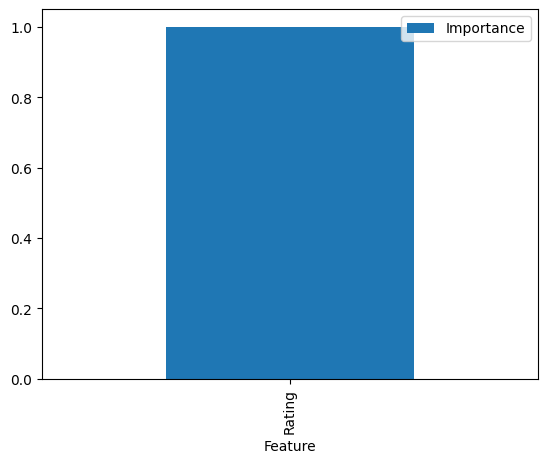

In [76]:
import matplotlib.pyplot as plt

importance.plot(
    x='Feature',
    y='Importance',
    kind='bar'
)

plt.show()

###4. KNN

In [51]:
from sklearn.neighbors import KNeighborsRegressor

model = KNeighborsRegressor()
model.fit(X_train,y_train)

KNeighborsRegressor()

### A)Train KNN Model

In [56]:
from sklearn.neighbors import KNeighborsRegressor

model = KNeighborsRegressor(n_neighbors=3)

model.fit(X_train, y_train)

KNeighborsRegressor(n_neighbors=3)

### B). Display Model

In [54]:
print(model)

KNeighborsRegressor()


###C). Make Predictions

In [58]:
# Example of adjusting n_neighbors
# Let's say we want to try n_neighbors = 1 instead of 3
from sklearn.neighbors import KNeighborsRegressor

# Instantiate the model with a different n_neighbors value
model_n1 = KNeighborsRegressor(n_neighbors=1)

# Fit the model to the training data
model_n1.fit(X_train, y_train)

# Make predictions with the new model
pred_n1 = model_n1.predict(X_test)

print(f"Predictions with n_neighbors=1: {pred_n1[:10]}")

# You would typically evaluate this model's performance
from sklearn.metrics import mean_absolute_error
mae_n1 = mean_absolute_error(y_test, pred_n1)
print(f"MAE with n_neighbors=1: {mae_n1}")

# For comparison, the original model (n_neighbors=3) had a MAE of 1.0

Predictions with n_neighbors=1: [7.]
MAE with n_neighbors=1: 1.0


In [57]:
pred = model.predict(X_test)

print(pred[:10])

[6.66666667]


### D). Actual vs Predicted

In [59]:
import pandas as pd

result = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": pred
})

result.head(10)

,Actual,Predicted
0,6,6.666667


### E). Calculate MAE

In [60]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, pred)

print("MAE =", mae)

MAE = 0.666666666666667


### F). Calculate MSE

In [61]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, pred)

print("MSE =", mse)

MSE = 0.44444444444444486


### G). Calculate RMSE

In [62]:
import numpy as np

rmse = np.sqrt(mse)

print("RMSE =", rmse)

RMSE = 0.666666666666667


### H). Calculate R² Score

In [63]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, pred)

print("R2 Score =", r2)

R2 Score = nan


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


### I). Scatter Plot (Actual vs Predicted)

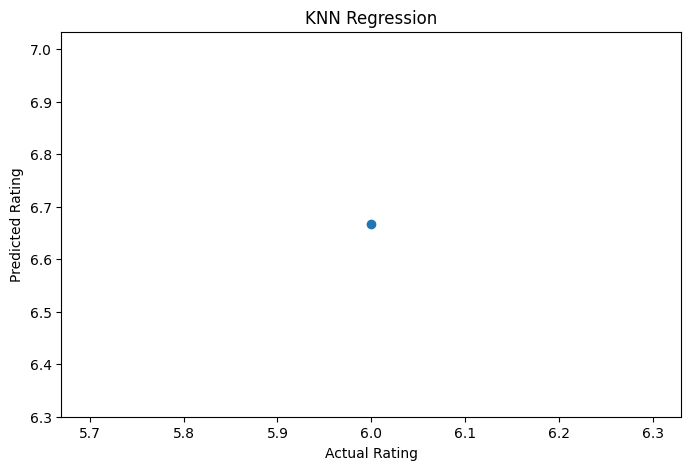

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(y_test, pred)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("KNN Regression")

plt.show()

###5. Support Vector Machine

In [52]:
from sklearn.svm import SVR

model = SVR()
model.fit(X_train,y_train)

SVR()

### A). Train SVR

In [65]:
from sklearn.svm import SVR

model = SVR()

model.fit(X_train, y_train)

SVR()

### B). Display Model

In [66]:
print(model)

SVR()


### C). Predict on Test Data

In [67]:
pred = model.predict(X_test)

print(pred[:10])

[6.10127654]


### D). Actual vs Predicted

In [68]:
import pandas as pd

result = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": pred
})

print(result.head(10))

   Actual  Predicted
0       6   6.101277


### E). MAE

In [69]:
from sklearn.metrics import mean_absolute_error

print("MAE =", mean_absolute_error(y_test, pred))

MAE = 0.10127654337391423


### F). MSE

In [70]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, pred)

print("MSE =", mse)

MSE = 0.01025693823776833


### G). RMSE

In [71]:
import numpy as np

print("RMSE =", np.sqrt(mse))

RMSE = 0.10127654337391423


### H). R² Score

In [72]:
from sklearn.metrics import r2_score

print("R2 Score =", r2_score(y_test, pred))

R2 Score = nan


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


### I). Display First 20 Predictions

In [73]:
for actual, predicted in zip(y_test.values[:20], pred[:20]):
    print("Actual:", actual, " Predicted:", round(predicted, 2))

Actual: 6  Predicted: 6.1


###6. Gradient Boosting

In [74]:
from sklearn.ensemble import GradientBoostingRegressor

model = GradientBoostingRegressor()



### A). Create Model

In [75]:
from sklearn.ensemble import GradientBoostingRegressor

model = GradientBoostingRegressor()

### B). Train Model

In [76]:
model.fit(X_train, y_train)

GradientBoostingRegressor()

### C). Display Model

In [77]:
print(model)

GradientBoostingRegressor()


### D). Make Predictions

In [78]:
pred = model.predict(X_test)

print(pred[:10])

[5.00004427]


### E). Actual vs Predicted

In [79]:
import pandas as pd

result = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": pred
})

print(result.head(10))

   Actual  Predicted
0       6   5.000044


### F). MAE

In [80]:
from sklearn.metrics import mean_absolute_error

print("MAE =", mean_absolute_error(y_test, pred))

MAE = 0.9999557310018528


### G). MSE

In [81]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, pred)

print("MSE =", mse)

MSE = 0.9999114639634497


### H). RMSE

In [82]:
import numpy as np

print("RMSE =", np.sqrt(mse))

RMSE = 0.9999557310018528


### I). R² Score

In [83]:
from sklearn.metrics import r2_score

print("R2 Score =", r2_score(y_test, pred))

R2 Score = nan


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


### J). Feature Importance

In [84]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

print(importance)

  Feature  Importance
0  Rating         1.0


### K). Plot Feature Importance

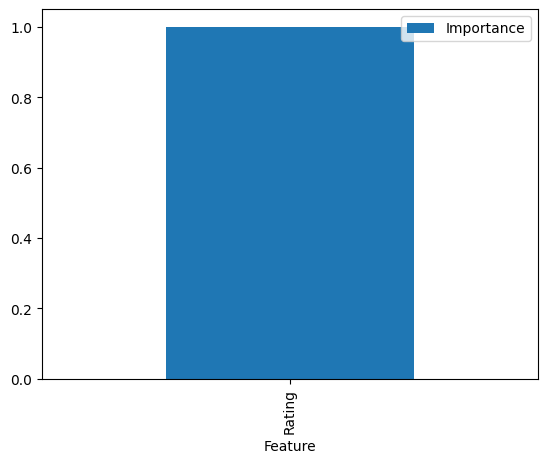

In [85]:
import matplotlib.pyplot as plt

importance.sort_values(
    by='Importance',
    ascending=False
).plot(
    x='Feature',
    y='Importance',
    kind='bar'
)

plt.show()

###7. XGBoost

In [55]:
from xgboost import XGBRegressor

model = XGBRegressor()

### A). Create Model

In [86]:
from xgboost import XGBRegressor

model = XGBRegressor()

### B). Train Model

In [87]:
model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

### C). Display Model

In [88]:
print(model)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)


### D). Predict

In [89]:
pred = model.predict(X_test)

print(pred[:10])

[5.0010533]


### E). Actual vs Predicted

In [90]:
import pandas as pd

result = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": pred
})

print(result.head(10))

   Actual  Predicted
0       6   5.001053


### F). MAE

In [91]:
from sklearn.metrics import mean_absolute_error

print("MAE =", mean_absolute_error(y_test, pred))

MAE = 0.9989466667175293


### G). MSE

In [92]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, pred)

print("MSE =", mse)

MSE = 0.9978944659233093


### H). RMSE

In [93]:
import numpy as np

print("RMSE =", np.sqrt(mse))

RMSE = 0.9989466782182668


### I). R² Score

In [94]:
from sklearn.metrics import r2_score

print("R2 Score =", r2_score(y_test, pred))

R2 Score = nan


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


### J). Feature Importance

In [95]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

print(importance)

  Feature  Importance
0  Rating         1.0


### K). Feature Importance Visualization

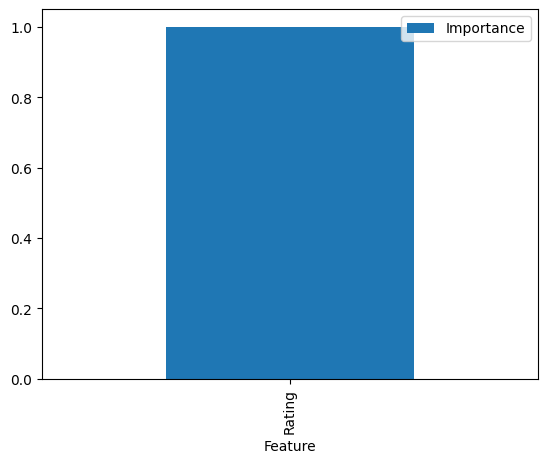

In [96]:
import matplotlib.pyplot as plt

importance.sort_values(
    by="Importance",
    ascending=False
).plot(
    x="Feature",
    y="Importance",
    kind="bar"
)

plt.show()

###8. Collaborative Filtering
Used in recommendation systems.

In [56]:
from sklearn.metrics.pairwise import cosine_similarity

### A). Simple Cosine Similarity

In [98]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

A = [[5, 3, 0]]
B = [[4, 2, 0]]

similarity = cosine_similarity(A, B)

print(similarity)

[[0.99705449]]


### B). Ratings Dataset

In [100]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Ratings.csv')

### C). Create User-Item Matrix:

In [103]:
user_item_matrix = df.pivot_table(
    index='Name',
    values='Rating'
)

user_item_matrix.fillna(0, inplace=True)

print(user_item_matrix.head())

        Rating
Name          
Girish     8.0
Kapil      6.0
Nandan     5.0
Sonali     7.0


### D). Compute Similarity

In [104]:
from sklearn.metrics.pairwise import cosine_similarity

similarity = cosine_similarity(user_item_matrix)

print(similarity)

[[1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]]


### F). Convert to DataFrame

In [105]:
similarity_df = pd.DataFrame(
    similarity,
    index=user_item_matrix.index,
    columns=user_item_matrix.index
)

print(similarity_df)

Name    Girish  Kapil  Nandan  Sonali
Name                                 
Girish     1.0    1.0     1.0     1.0
Kapil      1.0    1.0     1.0     1.0
Nandan     1.0    1.0     1.0     1.0
Sonali     1.0    1.0     1.0     1.0


###9. Matrix Factorization (SVD)

Most famous recommender algorithm.

In [57]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=20)

### A). Fit SVD

In [113]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=2)

# Fit SVD to the multi-item user-item matrix
svd.fit(user_item_matrix_multi_item)

TruncatedSVD()

In [114]:
transformed_matrix = svd.transform(user_item_matrix_multi_item)
print("Shape of transformed matrix:", transformed_matrix.shape)
display(transformed_matrix)

Shape of transformed matrix: (4, 2)


array([[ 8.57434169,  3.00396268],
       [ 7.14504032,  4.0601033 ],
       [ 5.13201173, -3.77581312],
       [ 6.88886915, -5.13714026]])

To effectively use algorithms like SVD for recommendation systems, your dataset needs to include specific 'Item' identifiers. The current `df` only has 'Name' and 'Rating', which implicitly treats each user's single rating as their interaction with a single, undefined item. For a true user-item matrix, you would need a dataset where each row represents a user's rating for a specific item, like this:

In [110]:
# Create a sample DataFrame that includes an 'Item' column
data = {
    'Name': ['Nandan', 'Kapil', 'Girish', 'Sonali', 'Nandan', 'Kapil', 'Girish', 'Sonali'],
    'Item': ['MovieA', 'MovieB', 'MovieC', 'MovieA', 'MovieB', 'MovieC', 'MovieA', 'MovieB'],
    'Rating': [5, 6, 8, 7, 4, 7, 6, 5]
}
sample_df_with_items = pd.DataFrame(data)
display(sample_df_with_items.head())

,Name,Item,Rating
0,Nandan,MovieA,5
1,Kapil,MovieB,6
2,Girish,MovieC,8
3,Sonali,MovieA,7
4,Nandan,MovieB,4


From such a DataFrame, you can then create a `user_item_matrix` where each row represents a user, each column represents an item, and the values are the ratings given by users to those items. Missing values (where a user hasn't rated an item) are typically filled with 0 or the user's average rating.

In [111]:
# Create a user-item matrix with multiple items
user_item_matrix_multi_item = sample_df_with_items.pivot_table(
    index='Name',
    columns='Item',
    values='Rating'
)

# Fill NaN values (items not rated by a user) with 0
user_item_matrix_multi_item.fillna(0, inplace=True)
display(user_item_matrix_multi_item.head())

Item,MovieA,MovieB,MovieC
Name,,,
Girish,6.0,0.0,8.0
Kapil,0.0,6.0,7.0
Nandan,5.0,4.0,0.0
Sonali,7.0,5.0,0.0


This `user_item_matrix_multi_item` now has multiple features (item columns) and would be suitable for algorithms like `TruncatedSVD`.

###10. K-Means Clustering

Group similar users.

In [58]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=5)

### A). Create KMeans Model

In [118]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=2, # Changed from 5 to 2 to resolve the ValueError
    random_state=42
)

### B). Fit Model

Use your features (X):

In [123]:
kmeans.fit(X)

KMeans(n_clusters=2, random_state=42)

### C). Display Model

In [120]:
print(kmeans)

KMeans(n_clusters=2, random_state=42)


### D). Display Cluster Labels

In [121]:
print(kmeans.labels_)

[1 0 1]


### E). Add Cluster Column

In [124]:
df['Cluster'] = kmeans.labels_

print(df.head())

     Name  Rating  Cluster
0  Nandan       5        0
1   Kapil       6        0
2  Girish       8        1
3  Sonali       7        1


### F). Cluster Centers

In [125]:
print(kmeans.cluster_centers_)

[[5.5]
 [7.5]]


### G). Inertia (WCSS)

In [126]:
print(kmeans.inertia_)

1.0


### H). Number of Iterations

In [127]:
print(kmeans.n_iter_)

2


### I). Predict Cluster for New Data

In [129]:
kmeans.predict([[7]]) # Example: Predicting the cluster for a new rating of 7. Only 1 feature should be passed.

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


array([1], dtype=int32)

### J). Cluster Counts

In [130]:
print(df['Cluster'].value_counts())

Cluster
0    2
1    2
Name: count, dtype: int64


### K). Visualization (if 2 Features)

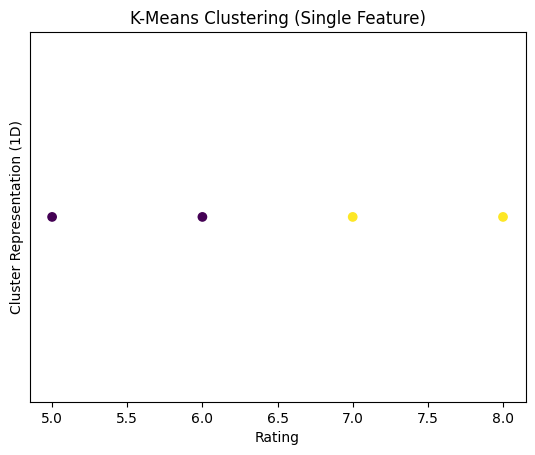

In [132]:
import matplotlib.pyplot as plt
import numpy as np

# Check if X has at least two features for a 2D scatter plot
if X.shape[1] >= 2:
    plt.scatter(
        X.iloc[:,0],
        X.iloc[:,1],
        c=kmeans.labels_
    )

    plt.xlabel(X.columns[0])
    plt.ylabel(X.columns[1])
    plt.title("K-Means Clustering (2 Features)")
elif X.shape[1] == 1:
    # For a single feature, plot it on the x-axis with a constant y-value to visualize clusters
    plt.scatter(
        X.iloc[:,0],
        np.zeros_like(X.iloc[:,0]), # Use zeros for y-axis to represent 1D clustering
        c=kmeans.labels_
    )
    plt.xlabel(X.columns[0])
    plt.ylabel("Cluster Representation (1D)") # Custom label for 1D visualization
    plt.title("K-Means Clustering (Single Feature)")
    plt.yticks([]) # Remove y-axis ticks as it's a conceptual 1D plot
else:
    print("Cannot visualize clusters: X has no features.")

plt.show()